# Exploración inicial del conjunto de obesidad

**Unidad II — Extracción de Conocimiento en Bases de Datos**  
Esta exploración lee el CSV original sin escribirlo. Las salidas y figuras se guardan fuera de `data/raw`. El análisis es descriptivo; no estima causas ni prevalencia poblacional. Una parte sustancial del dataset fue generada con SMOTE, según UCI.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
RAW = ROOT / "data/raw/ObesityDataSet_raw_and_data_sinthetic.csv"
FIGURES = ROOT / "docs/unidad_ii/figuras"
FIGURES.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(RAW)
expected_columns = ["Gender", "Age", "Height", "Weight", "family_history_with_overweight", "FAVC", "FCVC", "NCP", "CAEC", "SMOKE", "CH2O", "SCC", "FAF", "TUE", "CALC", "MTRANS", "NObeyesdad"]
assert list(df.columns) == expected_columns
assert df.shape == (2111, 17)
profile = {
    "rows": int(len(df)), "columns": int(len(df.columns)),
    "missing_cells": int(df.isna().sum().sum()),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "class_count": int(df["NObeyesdad"].nunique()),
    "dtypes": df.dtypes.astype(str).to_dict(),
}
print(json.dumps(profile, ensure_ascii=False, indent=2))
display(df.describe().T.round(3))

{
  "rows": 2111,
  "columns": 17,
  "missing_cells": 0,
  "exact_duplicate_rows": 24,
  "class_count": 7,
  "dtypes": {
    "Gender": "str",
    "Age": "float64",
    "Height": "float64",
    "Weight": "float64",
    "family_history_with_overweight": "str",
    "FAVC": "str",
    "FCVC": "float64",
    "NCP": "float64",
    "CAEC": "str",
    "SMOKE": "str",
    "CH2O": "float64",
    "SCC": "str",
    "FAF": "float64",
    "TUE": "float64",
    "CALC": "str",
    "MTRANS": "str",
    "NObeyesdad": "str"
  }
}


,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.313,6.346,14.00,19.947,22.778,26.000,61.00
Height,2111.0,1.702,0.093,1.45,1.630,1.700,1.768,1.98
Weight,2111.0,86.586,26.191,39.00,65.473,83.000,107.431,173.00
FCVC,2111.0,2.419,0.534,1.00,2.000,2.386,3.000,3.00
NCP,2111.0,2.686,0.778,1.00,2.659,3.000,3.000,4.00
CH2O,2111.0,2.008,0.613,1.00,1.585,2.000,2.477,3.00
FAF,2111.0,1.010,0.851,0.00,0.125,1.000,1.667,3.00
TUE,2111.0,0.658,0.609,0.00,0.000,0.625,1.000,2.00


In [2]:
categorical = ["Gender", "family_history_with_overweight", "FAVC", "CAEC", "SMOKE", "SCC", "CALC", "MTRANS", "NObeyesdad"]
for column in categorical:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False).to_string())

numeric = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
outlier_screen = {}
for column in numeric:
    q1, q3 = df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[column] < q1 - 1.5 * iqr) | (df[column] > q3 + 1.5 * iqr)
    outlier_screen[column] = int(mask.sum())
print("\nCandidatos al criterio 1.5×IQR; son una alerta descriptiva, no una orden de eliminación:")
print(outlier_screen)


Gender
Gender
Male      1068
Female    1043

family_history_with_overweight
family_history_with_overweight
yes    1726
no      385

FAVC
FAVC
yes    1866
no      245

CAEC
CAEC
Sometimes     1765
Frequently     242
Always          53
no              51

SMOKE
SMOKE
no     2067
yes      44

SCC
SCC
no     2015
yes      96

CALC
CALC
Sometimes     1401
no             639
Frequently      70
Always           1

MTRANS
MTRANS
Public_Transportation    1580
Automobile                457
Walking                    56
Motorbike                  11
Bike                        7

NObeyesdad
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272

Candidatos al criterio 1.5×IQR; son una alerta descriptiva, no una orden de eliminación:
{'Age': 168, 'Height': 1, 'Weight': 1, 'FCVC': 0, 'NCP': 579, 'CH2O': 0, 'FAF': 0, 'TUE': 0}


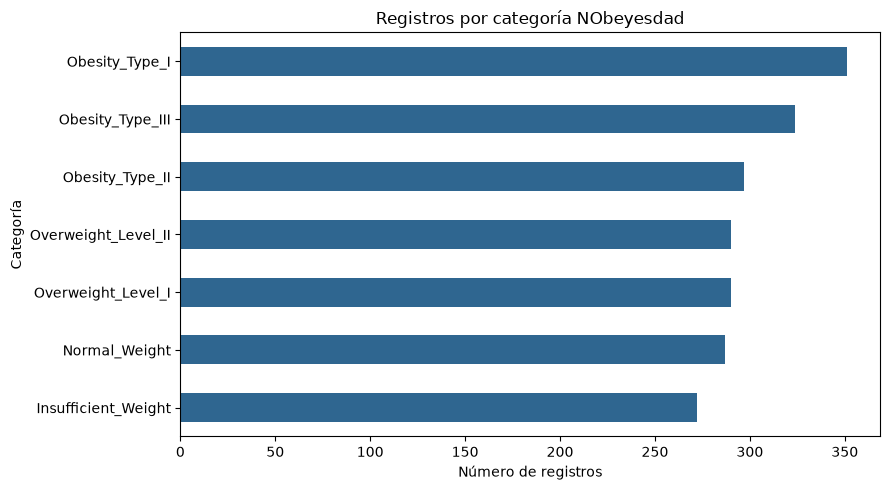

NObeyesdad
Insufficient_Weight    272
Normal_Weight          287
Overweight_Level_I     290
Overweight_Level_II    290
Obesity_Type_II        297
Obesity_Type_III       324
Obesity_Type_I         351


In [3]:
class_counts = df["NObeyesdad"].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
class_counts.plot(kind="barh", ax=ax, color="#2F6690")
ax.set_title("Registros por categoría NObeyesdad")
ax.set_xlabel("Número de registros")
ax.set_ylabel("Categoría")
fig.tight_layout()
fig.savefig(FIGURES / "distribucion_n_obesidad.png", dpi=160, bbox_inches="tight")
plt.show()
print(class_counts.to_string())

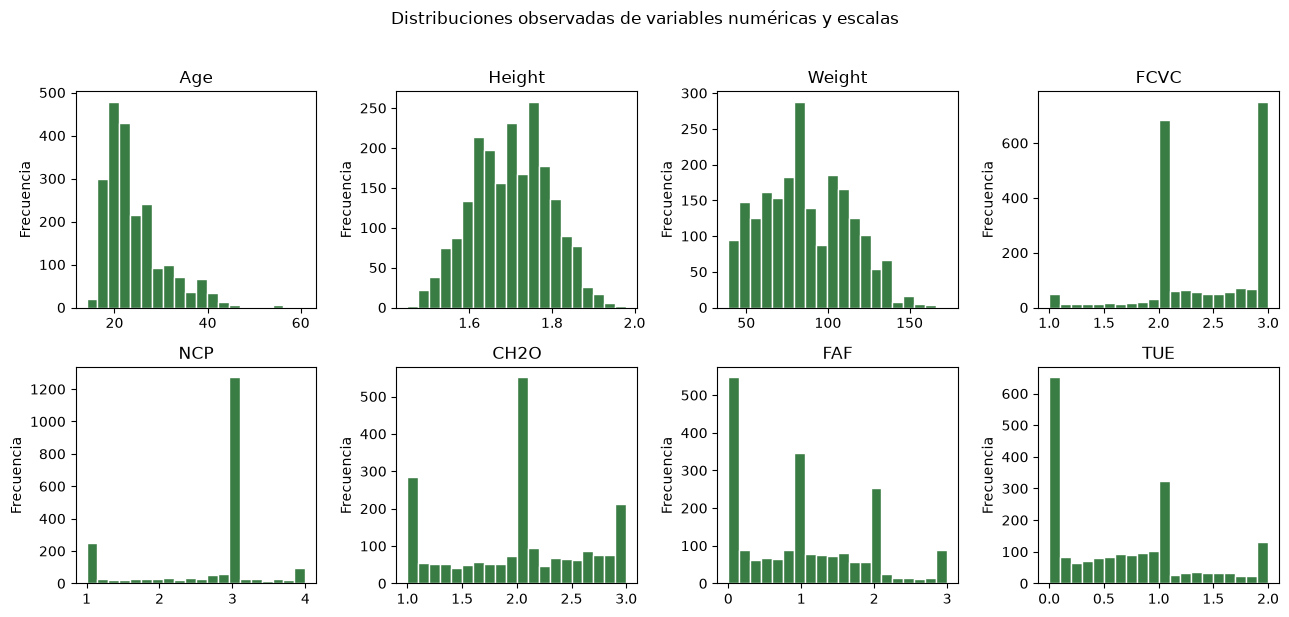

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.313,6.346,14.00,19.947,22.778,26.000,61.00
Height,2111.0,1.702,0.093,1.45,1.630,1.700,1.768,1.98
Weight,2111.0,86.586,26.191,39.00,65.473,83.000,107.431,173.00
FCVC,2111.0,2.419,0.534,1.00,2.000,2.386,3.000,3.00
NCP,2111.0,2.686,0.778,1.00,2.659,3.000,3.000,4.00
CH2O,2111.0,2.008,0.613,1.00,1.585,2.000,2.477,3.00
FAF,2111.0,1.010,0.851,0.00,0.125,1.000,1.667,3.00
TUE,2111.0,0.658,0.609,0.00,0.000,0.625,1.000,2.00


In [4]:
numeric = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for column, ax in zip(numeric, axes.flat):
    ax.hist(df[column], bins=20, color="#3A7D44", edgecolor="white")
    ax.set_title(column)
    ax.set_ylabel("Frecuencia")
fig.suptitle("Distribuciones observadas de variables numéricas y escalas", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "distribuciones_numericas.png", dpi=160, bbox_inches="tight")
plt.show()
display(df[numeric].describe().T.round(3))

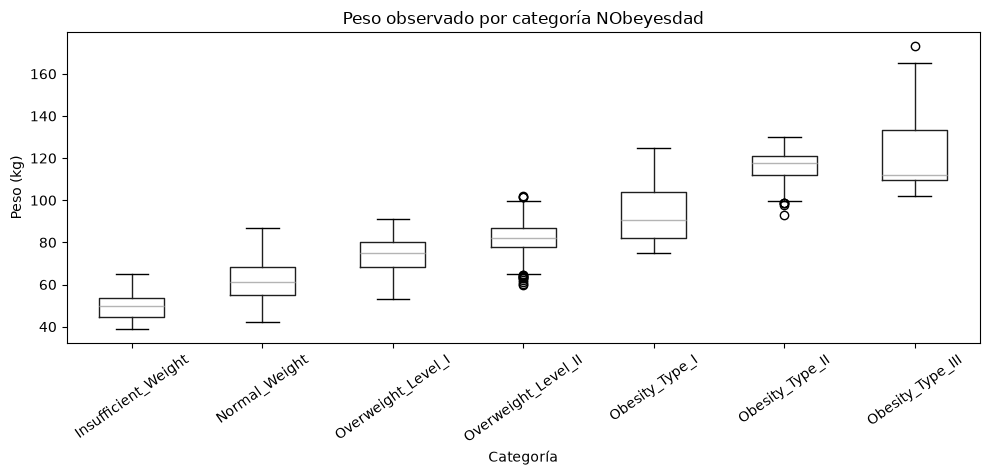

NObeyesdad,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
family_history_with_overweight,,,,,,,
no,146,132,81,18,7,1,0
yes,126,155,209,272,344,296,324


In [5]:
order = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II", "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
df["NObeyesdad"] = pd.Categorical(df["NObeyesdad"], categories=order, ordered=True)
fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(column="Weight", by="NObeyesdad", ax=ax, grid=False, rot=35)
ax.set_title("Peso observado por categoría NObeyesdad")
ax.set_xlabel("Categoría")
ax.set_ylabel("Peso (kg)")
fig.suptitle("")
fig.tight_layout()
fig.savefig(FIGURES / "peso_por_categoria.png", dpi=160, bbox_inches="tight")
plt.show()
contingency = pd.crosstab(df["family_history_with_overweight"], df["NObeyesdad"])[order]
display(contingency)

## Lectura descriptiva

La etiqueta tiene siete categorías y los conteos deben leerse como composición de este dataset, no como prevalencia de una población. El boxplot muestra cómo se distribuye `Weight` entre las etiquetas publicadas; esa relación no es evidencia independiente de asociación porque el peso es parte de la información usada para definir niveles antropométricos. La tabla de antecedentes familiares es descriptiva y no establece efecto causal.

Las columnas codificadas como escalas (por ejemplo, FCVC, CH2O, FAF y TUE) presentan decimales en algunas filas. No se redondean: el dataset contiene registros sintéticos y la conversión cambiaría valores observados. Los 24 duplicados exactos se preservan en el conjunto procesado; Unidad III debe mantener copias idénticas en la misma partición al evaluar modelos.